In [122]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080128
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")


[Conda 环境] env_20244080128
[学号]       20244080128
[机器指纹] e28ba7c1e7aa42dd
[RUN_ID]   20244080128-e28ba7c1e7aa42dd


# 实验一

## 1

In [123]:
import numpy as np

# 1) 创建三种类型的数组
arr_int   = np.array([1, 2, 3, 4])
arr_float = np.array([1.5, 2.5, 3.5, 4.5])
arr_bool  = np.array([True, False, True, False])

# 2) 用循环批量输出属性，代码更简洁
for name, arr in [("整数", arr_int), ("浮点", arr_float), ("布尔", arr_bool)]:
    print(f"[{name}数组] dtype={arr.dtype}, shape={arr.shape}, ndim={arr.ndim}")

[整数数组] dtype=int64, shape=(4,), ndim=1
[浮点数组] dtype=float64, shape=(4,), ndim=1
[布尔数组] dtype=bool, shape=(4,), ndim=1


## 2

**改变形状的条件：**
1. 原数组元素总数 `size = 12`，目标形状元素总数必须等于 12：
   - `(3,4)`：3×4 = 12 ✅
   - `(2,3,2)`：2×3×2 = 12 ✅
   - `(5,3)`：5×3 = 15 ≠ 12 ❌ → 触发 ValueError（如上"预期报错"所示）。
2. 元素按行优先顺序（C 序）依次填入新形状：
   如 arr_34 第1行 0~3、第2行 4~7、第3行 8~11。
3. reshape 返回新视图，不修改原 arr_tt（原数组仍为长度12的一维数组）。

In [124]:
import numpy as np

arr_tt = np.arange(12)
print("arr_tt =\n", arr_tt, "\nshape =", arr_tt.shape)

arr_34 = arr_tt.reshape(3, 4)
print("\narr_34 =\n", arr_34, "\nshape =", arr_34.shape)

arr_232 = arr_tt.reshape(2, 3, 2)
print("\narr_232 =\n", arr_232, "\nshape =", arr_232.shape)

# 验证：元素总数不相等时 reshape 报错
try:
    arr_tt.reshape(5, 3)
except ValueError as e:
    print("\n【预期报错】元素总数不等，无法 reshape：", e)

arr_tt =
 [ 0  1  2  3  4  5  6  7  8  9 10 11] 
shape = (12,)

arr_34 =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] 
shape = (3, 4)

arr_232 =
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]] 
shape = (2, 3, 2)

【预期报错】元素总数不等，无法 reshape： cannot reshape array of size 12 into shape (5,3)


## 3

**结果解释：**

1. **取第2行（`arr_34[1, :]`）**：结果为 `[4 5 6 7]`，形状为 `(4,)`。
   - 原理：使用了整数下标 `1`，这代表“抽走”这一维，因此数组从二维降为了一维。

2. **取第1至第3列（`arr_34[:, 0:3]`）**：结果为 3×3 的矩阵，形状为 `(3, 3)`。
   - 原理：使用了切片 `0:3`（左闭右开，即索引 0,1,2 列）。切片代表“框选范围”，因此保留了原有的二维结构。

3. **取大于6的元素（`arr_34[mask]`）**：结果为 `[7 8 9 10 11]`，形状为 `(5,)`。
   - 原理：`mask` 是一个与原数组形状相同的布尔矩阵。布尔索引会扫描所有位置，把对应为 `True` 位置的元素挑出来并排成一条线。因此，不论原数组是几维，布尔索引的结果**始终是一维数组**，其长度等于 `True` 的个数（即 5 个）。

In [125]:
arr_34_h = arr_34[1,:]
arr_34_l = arr_34[:,0:3]
print(arr_34_h)
print(arr_34_l)
mask = arr_34 > 6
arr_34_t = arr_34[mask]
print(arr_34_t)
print(arr_34_t.shape)

[4 5 6 7]
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
[ 7  8  9 10 11]
(5,)


## 4

In [126]:
b = np.arange(10)
mask = (b > 7) | (b < 2)
b_r = b[mask]
print(b_r)
mask = (b > 3) & (b < 7)
b_t = b[mask]
print(b_t)

[0 1 8 9]
[4 5 6]


## 5

**结果解释与区别说明：**

1. **逐元素乘法（`*` 与 `np.multiply`）**：
   - 运算规则：两个矩阵对应位置的元素直接相乘，即 \(C_{ij} = A_{ij} \times B_{ij}\)。数学上称为 Hadamard 积。
   - 结果矩阵的形状与原矩阵保持一致（本题为 2×2）。
   - 例如左上角元素为：\(1 \times 5 = 5\)。

2. **矩阵乘法（`@` 与 `np.matmul`）**：
   - 运算规则：左矩阵的“行”与右矩阵的“列”对应元素相乘后求和（行乘列再相加）。即 \(C_{ij} = \sum A_{ik} \times B_{kj}\)。这是标准的线性代数矩阵乘法。
   - 结果矩阵的形状由两个矩阵的维度决定（(m×n) 乘 (n×p) 得到 m×p，本题 2×2 乘 2×2 得到 2×2）。
   - 例如左上角元素为：\(A\) 的第 1 行 \([1, 2]\) 与 \(B\) 的第 1 列 \([5, 7]\) 的点乘，即 \(1 \times 5 + 2 \times 7 = 19\)。

3. **总结**：`*` 是位置对齐的纯数值乘法，`@` 是带有线性变换意义的代数乘法。在 NumPy 中，两者不能混用。

In [127]:
import numpy as np

# 构造两个 2x2 数组
A = np.array([[1, 2],
              [3, 4]])
B = np.array([[5, 6],
              [7, 8]])

print("矩阵 A =\n", A)
print("矩阵 B =\n", B)

# 1. 逐元素乘法
print("\n--- 逐元素乘法 ---")
mul_1 = A * B
mul_2 = np.multiply(A, B)
print("A * B =\n", mul_1)
print("np.multiply(A, B) =\n", mul_2)

# 2. 矩阵乘法
print("\n--- 矩阵乘法 ---")
mat_1 = A @ B
mat_2 = np.matmul(A, B)
print("A @ B =\n", mat_1)
print("np.matmul(A, B) =\n", mat_2)

矩阵 A =
 [[1 2]
 [3 4]]
矩阵 B =
 [[5 6]
 [7 8]]

--- 逐元素乘法 ---
A * B =
 [[ 5 12]
 [21 32]]
np.multiply(A, B) =
 [[ 5 12]
 [21 32]]

--- 矩阵乘法 ---
A @ B =
 [[19 22]
 [43 50]]
np.matmul(A, B) =
 [[19 22]
 [43 50]]


# 实验二

## 1

**结果解释：**
1. **固定随机种子**：使用 `np.random.seed(42)` 确保了每次运行代码生成的伪随机数序列完全一致，保证了实验的**可复现性**。
2. **截断处理**：理论上的正态分布是没有上下限的，但在现实中（如成绩）存在 0~100 的边界。`np.clip(scores, 0, 100)` 将所有小于 0 的值变成了 0，大于 100 的值变成了 100。
3. **统计指标**：均值（70.18）和标准差（9.75）都非常接近我们设定的理论值（70 和 10）。最大值变成了 100，说明 `np.clip` 成功拦截了部分超出的异常值。

In [128]:
import numpy as np
np.random.seed(42)
scores = np.random.normal(loc = 70,scale = 10, size = 1000)
scores = np.clip(scores, 0, 100)

print("样本数：", len(scores))
print("最小值：", scores.min())
print("最大值：", scores.max())
print("均值：", scores.mean())
print("标准差：", scores.std())
print("极差：", scores.max() - scores.min())

样本数： 1000
最小值： 37.58732659930927
最大值： 100.0
均值： 70.18400443523215
标准差： 9.755086339034765
极差： 62.41267340069073


## 2

**结果解释与抽样对比：**
1. **均匀抽样**：不使用 `p` 参数时，默认每个元素被抽中的概率完全相等（均为 1/10）。输出结果 `[3 2 5 6 1]` 中大小数字分布均匀。
2. **加权抽样**：通过 `p=weights` 传入了概率数组，数字越大（如 10、9、8），其对应的概率值越大（概率为 \(i/55\)）。输出结果 `[4 1 8 10 9]` 明显更容易抽中大数字。
3. **不放回**：两次抽样均设置了 `replace=False`，保证了同一个数字不会在单次抽样中重复出现。在加权且不放回的情况下，NumPy 会自动把抽走元素的概率剔除并对剩余概率重新归一化。

In [129]:
arr = np.arange(1, 11)  # [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
uniform_sample = np.random.choice(arr, size=5, replace=False)
print(uniform_sample)
# 权重直接用数字本身，但是要除以总和，让它变成概率
weights = arr / arr.sum()
# 或者用 np.ones(10) 也可以，但题目要求"按整数大小成比例"
weighted_sample = np.random.choice(arr, size=5, replace=False, p=weights)
print(weighted_sample)

[ 4  9  2  6 10]
[10  2  8  9  6]


## 3

**结果解释与区别：**
1. **`np.random.permutation(arr)`**：用于生成一个随机排列的新数组。从输出可以看出，它**不修改原数组**，原数组 `arr` 依然保持 `[1, 2, 3, ..., 10]` 的原始顺序，打乱后的结果是一个独立的副本。
2. **`np.random.shuffle(arr)`**：用于**原地打乱（In-place）**数组。从输出可以看出，它的返回值为 `None`，因为它直接在原数组的内存上进行修改，打印原数组时发现 `arr` 的顺序已经被彻底打乱了。
3. **使用建议**：如果不希望破坏原始数据，用 `permutation`；如果数据量极大且不需要保留原顺序，用 `shuffle` 可以节省内存。

In [130]:
# 先定义一个用来测试的数组
arr = np.arange(1, 11)
print("原始数组：", arr)

# 1. 用 permutation 随机排列
print("\n--- np.random.permutation ---")
perm_res = np.random.permutation(arr)
print("permutation 返回的新数组：", perm_res)
print("打印原数组 (看看变没变)：", arr)

# 2. 用 shuffle 原地打乱
print("\n--- np.random.shuffle ---")
shuffle_res = np.random.shuffle(arr)
print("shuffle 的返回值：", shuffle_res)
print("打印原数组 (看看变没变)：", arr)

原始数组： [ 1  2  3  4  5  6  7  8  9 10]

--- np.random.permutation ---
permutation 返回的新数组： [ 8  1  6  5  2  9 10  3  7  4]
打印原数组 (看看变没变)： [ 1  2  3  4  5  6  7  8  9 10]

--- np.random.shuffle ---
shuffle 的返回值： None
打印原数组 (看看变没变)： [ 1  5  8  7 10  6  2  4  9  3]


## 4

**结果解释：**
1. **普通均值为 `nan`**：在 NumPy 中，`np.nan`（Not a Number）具有“传染性”。任何数与 `nan` 进行算术运算（如加法、求平均），结果都会变成 `nan`。因此调用普通的 `scores_nan.mean()` 直接得到了 `nan`。
2. **忽略缺失值的均值**：使用 `np.nanmean()` 函数会自动跳过所有的 `nan` 值，只对剩下的 997 个有效样本求均值（算得约 69.42，非常接近理论均值 70），这才是真实有效的统计量。
3. **缺失值统计**：`np.isnan(scores_nan)` 会返回一个布尔数组（`True` 代表是缺失值），利用布尔值 `True` 会被当作 1、`False` 当作 0 的特性，对其调用 `.sum()` 即可快速统计出缺失值个数为 3 个。

**拓展**：除了 `np.nanmean`，NumPy 还提供了 `np.nansum`、`np.nanstd`、`np.nanmax` 等一系列以 `nan` 开头的函数，专门用于忽略缺失值进行统计计算。

In [131]:

# 1. 生成数据
np.random.seed(42)
scores_nan = np.random.normal(loc=70, scale=10, size=1000)
scores_nan = np.clip(scores_nan, 0, 100)

# 2. 设置缺失值
scores_nan[9] = np.nan
scores_nan[19] = np.nan
scores_nan[29] = np.nan

# 3. 计算均值
print("普通均值：", scores_nan.mean())
scores_nan_c = np.nanmean(scores_nan)
print("忽略缺失值的均值：", scores_nan_c)

# 4. 统计缺失值个数
print("缺失值个数：", np.isnan(scores_nan).sum())


普通均值： nan
忽略缺失值的均值： 70.19620743160239
缺失值个数： 3


## 5

**结果解释：**
1. **表格变量创建**：使用了 `pandas` 的 `DataFrame` 来构建内存中的二维表格数据结构。将 `np.arange(1, 1001)` 生成的序号与含缺失值的 `scores_nan` 数组按列组合。
2. **内存操作**：整个过程中数据始终存储在内存（RAM）中，没有调用 `to_csv()` 等方法写入磁盘，满足了“不写入磁盘”的要求，适合后续在实验4中直接进行数据分析操作。
3. **缺失值检查**：通过 `isna()` 方法可以快速筛选出含有 `NaN` 的行，验证了第 10、20、30 号样本的成绩确实为缺失值。

In [132]:
import pandas as pd

# 1. 用字典构建 DataFrame 表格
df_scores = pd.DataFrame({
    "序号": np.arange(1, 1001),
    "成绩": scores_nan
})

# 2. 预览前 5 行
print("表格预览（前 5 行）：\n", df_scores.head())

# 3. 查看表格整体形状c
print("\n表格形状：", df_scores.shape)

# 4. 挑出包含缺失值的行
print("\n包含缺失值的行：")
print(df_scores[df_scores["成绩"].isna()])

表格预览（前 5 行）：
    序号         成绩
0   1  74.967142
1   2  68.617357
2   3  76.476885
3   4  85.230299
4   5  67.658466

表格形状： (1000, 2)

包含缺失值的行：
    序号  成绩
9   10 NaN
19  20 NaN
29  30 NaN


# 实验三

## 1

In [133]:
import numpy as np
from scipy.linalg import solve

# 1. 定义 A 和 b
A = np.array([[3, 1], 
              [1, 2]])
b = np.array([9, 8])

# 2. 求解
x = solve(A, b)
print("方程组的解为：", x)
print(f"即 x = {x[0]}, y = {x[1]}")

# 3. 验证
b_check = A @ x
print("\n代入验证 A @ x =", b_check)
print("与原向量 b 是否一致：", np.allclose(b_check, b))

方程组的解为： [2. 3.]
即 x = 2.0, y = 3.0

代入验证 A @ x = [9. 8.]
与原向量 b 是否一致： True


## 2

In [134]:
from scipy.optimize import root
import numpy as np  # 需要用到 abs() 或者一些验证时可以辅助

# 1. 定义函数
def f(x):
    return x**2 - 2

# 2. 求正根（初始猜测 x0=1）
print("--- 求正根 ---")
res_pos = root(f, x0=1)
print("是否成功：", res_pos.success)
print("求得的正根：", res_pos.x)
print("代入后的函数值：", f(res_pos.x))  # 应该极接近 0

# 3. 求负根（初始猜测 x0=-1）
print("\n--- 求负根 ---")
res_neg = root(f, x0=-1)
print("是否成功：", res_neg.success)
print("求得的负根：", res_neg.x)
print("代入后的函数值：", f(res_neg.x))

--- 求正根 ---
是否成功： True
求得的正根： [1.41421356]
代入后的函数值： [-8.8817842e-16]

--- 求负根 ---
是否成功： True
求得的负根： [-1.41421356]
代入后的函数值： [-8.8817842e-16]


## 3

**结果解释：**
1. **极小值点**：求得极值点 `x = [-0.50000001]`，极其接近理论值 `x = -0.5`。
2. **极小值**：求得 `f(x) = 1.75`，与解析计算的结果完全一致。
3. **为什么选择 x0=0**：由于二次函数只有一个极小值点（全局最优），所以初始猜测值选任何数（比如 0），优化器都能顺着梯度找到真实的谷底。

In [135]:
from scipy.optimize import minimize

# 1. 定义函数
def f(x):
    return x**2 + x + 2

# 2. 调用 minimize 求解
res = minimize(f, x0=0)
print("是否成功：", res.success)
print("极小值点 x =", res.x)
print("极小值 f(x) =", res.fun)

# 3. 对比解析结果
print("\n--- 对比解析结果 ---")
print("理论极小值点 x = -0.5")
print("理论极小值 f(x) = 1.75")

是否成功： True
极小值点 x = [-0.50000001]
极小值 f(x) = 1.75

--- 对比解析结果 ---
理论极小值点 x = -0.5
理论极小值 f(x) = 1.75


## 4

**结果解释：**
1. **样本对比**：样本1的均值约为 -0.10（理论值 0），样本2的均值约为 1.02（理论值 1），直观上二者存在差异。
2. **检验结果**：t 统计量为 -8.55，说明样本1均值显著低于样本2；p 值为 `3.29e-15`。
3. **统计判断**：在 0.05 的显著性水平下，p 值远小于 0.05，因此**拒绝原假设**（原假设为两组数据均值相等），认为这两组独立样本存在**统计学上的显著差异**。

In [136]:
import numpy as np
from scipy.stats import ttest_ind

np.random.seed(42)  # 固定种子

# 1. 生成样本
sample1 = np.random.normal(loc=0, scale=1, size=100)
sample2 = np.random.normal(loc=1, scale=1, size=100)

print("样本1均值：", sample1.mean())
print("样本2均值：", sample2.mean())

# 2. 独立样本 t 检验
res = ttest_ind(sample1, sample2)
print("\n--- t 检验结果 ---")
print("t 统计量：", res.statistic)
print("p 值：", res.pvalue)

# 3. 结论判断
if res.pvalue < 0.05:
    print("结论：p < 0.05，拒绝原假设，两组数据存在显著差异。")
else:
    print("结论：p >= 0.05，不能拒绝原假设，无显著差异。")

样本1均值： -0.10384651739409384
样本2均值： 1.0223045870499237

--- t 检验结果 ---
t 统计量： -8.55145994324873
p 值： 3.2929614287036995e-15
结论：p < 0.05，拒绝原假设，两组数据存在显著差异。


## 5

**结果解释：**
1. **直方图**：展示了剔除缺失值后的有效成绩分布。数据呈近似钟形（正态分布），集中在 60~80 分区间，直观展示了数据的集中趋势和离散程度。
2. **箱线图**：进一步展示了成绩的统计特征。中间的线代表中位数（约 70 分），箱体代表 25%~75% 的四分位距（大部分人的成绩范围），两端的须线展示了正常数据范围，未见明显的离群点（因为没有超出边界的异常值）。
3. **折线图**：在 0~5 的区间内，\(y=x\) 呈线性增长，\(y=x^2\) 呈抛物线增长，\(y=x^3\) 呈指数级增长。通过 `plt.legend()` 成功添加了图例，直观对比了不同幂函数的增长速度。

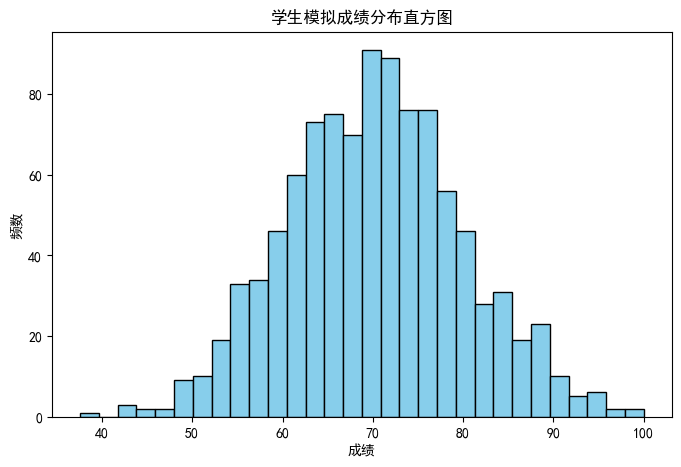

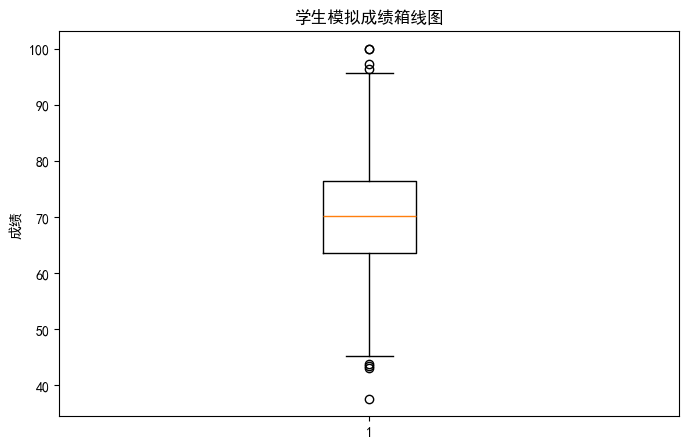

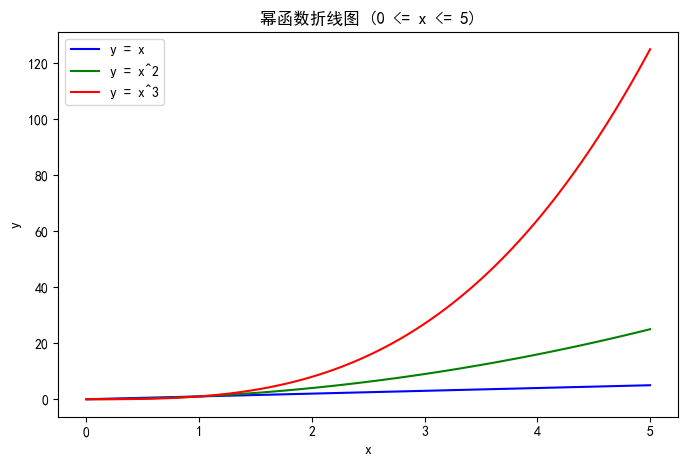

In [137]:
import matplotlib.pyplot as plt

# 解决中文显示问题
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 画直方图 (使用实验2里的有效成绩 scores_nan)
plt.figure(figsize=(8, 5))
plt.hist(scores_nan[~np.isnan(scores_nan)], bins=30, color='skyblue', edgecolor='black')
plt.title("学生模拟成绩分布直方图")
plt.xlabel("成绩")
plt.ylabel("频数")
plt.show()

plt.figure(figsize=(8, 5))
# 画箱线图，同样记得剔除 nan
plt.boxplot(scores_nan[~np.isnan(scores_nan)])
plt.title("学生模拟成绩箱线图")
plt.ylabel("成绩")
plt.show()

# 生成 x 数据
x = np.linspace(0, 5, 100)
y1 = x
y2 = x**2
y3 = x**3

plt.figure(figsize=(8, 5))
plt.plot(x, y1, label='y = x', color='blue')
plt.plot(x, y2, label='y = x^2', color='green')
plt.plot(x, y3, label='y = x^3', color='red')

plt.title("幂函数折线图 (0 <= x <= 5)")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()  # 显示图例
plt.show()

# 实验四

## 1

**结果解释：**
1. **数据结构**：通过 `set_index("Name")` 将姓名设为了行索引，方便后续用 `loc` 按姓名直接检索。
2. **新增列**：利用 pandas 的向量化特性，直接将三科成绩列相加得到 `Total`，再除以 3 得到 `Average`，无需写循环。
3. **统计信息**：`df.describe()` 自动对数值列进行了统计，得出了各科的均值（如 Math 均值约 79.8）、标准差及四分位数等，直观反映了整体成绩的集中与离散趋势。

In [138]:
import pandas as pd

records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

# 1. 创建 DataFrame
df = pd.DataFrame(records).set_index("Name")

# 2. 计算总分和平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

# 3. 打印基本信息
print("行索引：", df.index)
print("列名：", df.columns)
print("\n前 3 行：\n", df.head(3))
print("\n基本统计信息：\n", df.describe())

行索引： Index(['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank'], dtype='object', name='Name')
列名： Index(['Group', 'Math', 'English', 'Python', 'Total', 'Average'], dtype='object')

前 3 行：
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  27

## 2

**结果解释：**
1. **`loc` 与 `iloc` 的区别**：`df.loc["Carol"]` 是基于行标签（姓名）读取，`df.iloc[2]` 是基于行位置（第3行，索引从0开始）读取。两者都能成功定位到 Carol 的数据。
2. **筛选逻辑**：`df[df["Average"] >= 80]` 使用了布尔索引，筛选出了平均分大于等于 80 分的学生（Alice、Carol、Eva、Frank）。注意这里必须使用 `>=` 以包含临界值 80。

In [139]:
print(df.loc[["Carol"]])
print(df.iloc[[2]])
print(df[df["Average"] >= 80])

      Group  Math  English  Python  Total    Average
Name                                                
Carol     B    91       85      89    265  88.333333
      Group  Math  English  Python  Total    Average
Name                                                
Carol     B    91       85      89    265  88.333333
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


## 3

**结果解释：**
1. **`axis=0`（列均值）**：沿纵向（跨行）计算，求出了 Math、English、Python 三科的全班平均分，分别为 79.83、80.83、83.67。
2. **`axis=1`（行均值）**：沿横向（跨列）计算，求出了每名学生的三科平均分，结果与我们之前单独计算的 `Average` 列完全一致，验证了计算逻辑的正确性。

In [140]:
# 1. 列均值（只取三科，因为算总分和平均分的均值没意义）
subjects_mean = df[["Math", "English", "Python"]].mean(axis=0)
print("三科列均值：\n", subjects_mean)

# 2. 行均值（注意这里用 axis=1）
row_mean = df[["Math", "English", "Python"]].mean(axis=1)
print("\n每名学生的行均值：\n", row_mean)

三科列均值：
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生的行均值：
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


## 4

**结果解释：**
1. **`apply` 最高分**：通过设置 `axis=1`，对每名学生的三科成绩应用内置 `max` 函数，成功找出了每人单科最高分。例如 Alice 最高分是 95（Python）。
2. **`agg` 聚合**：传入列表 `['min', 'mean', 'max']`，一次性得出了三科的最低、平均和最高分。省去了逐列多次调用统计函数的麻烦。
3. **`rank` 排名**：使用 `rank(ascending=False)` 进行降序排名，平均分最高的 Alice（91分）排名第 1，符合日常成绩排名的逻辑。

In [141]:
# 1. apply 计算最高分
df["Max_Score"] = df[["Math", "English", "Python"]].apply(max, axis=1)
print("--- 每名学生三科最高分 ---")
print(df["Max_Score"])

# 2. agg 一次性聚合
print("\n--- 三科聚合统计（最小/均值/最大）---")
agg_res = df[["Math", "English", "Python"]].agg(['min', 'mean', 'max'])
print(agg_res)

# 3. rank 排名（降序，分数高的排前面）
df["Rank"] = df["Average"].rank(ascending=False)
print("\n--- 按平均分降序排名 ---")
print(df[["Average", "Rank"]])

--- 每名学生三科最高分 ---
Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: Max_Score, dtype: int64

--- 三科聚合统计（最小/均值/最大）---
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

--- 按平均分降序排名 ---
         Average  Rank
Name                  
Alice  91.000000   1.0
Bob    73.333333   5.0
Carol  88.333333   2.0
David  69.333333   6.0
Eva    85.666667   3.0
Frank  81.000000   4.0


## 5

**结果解释：**
1. **分组人数**：使用 `groupby("Group").size()` 得出 A 组和 B 组各有 3 名学生。
2. **分组均值**：使用 `groupby("Group").mean()` 算出了各组的三科平均分。A 组的 Python 均分为 87.0，B 组为 80.33。
3. **`transform` 的作用**：`transform('mean')` 与直接 `mean()` 不同，它不会只返回两行汇总结果，而是**保持了原数据的行数**（6行），将所在组的均值分别填入每一行，生成了新列 `Group_Python_Mean`，非常便于后续做组内对比分析。

In [142]:
# 1. 统计每组人数
group_counts = df.groupby("Group").size()
print("--- 每组人数 ---")
print(group_counts)

# 2. 统计每组三科平均分
group_means = df.groupby("Group")[["Math", "English", "Python"]].mean()
print("\n--- 每组三科平均分 ---")
print(group_means)

# 3. transform 增加组平均分列
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform('mean')
print("\n--- 每行的组内 Python 平均分 ---")
print(df[["Group", "Python", "Group_Python_Mean"]])

--- 每组人数 ---
Group
A    3
B    3
dtype: int64

--- 每组三科平均分 ---
            Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

--- 每行的组内 Python 平均分 ---
      Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


## 6

**结果解释：**
1. **分组过滤**：`groupby("Group").filter(...)` 是对**组**进行筛选，而不是对单独的行。`lambda x` 中的 `x` 代表每个组的子表。
2. **筛选结果**：A组的 Python 均分为 87.0，B组为 80.33，两者均满足 `>= 80` 的条件。因此 A 组和 B 组的所有行都被成功保留，输出结果与原表完全一致。如果有一组的均值低于 80，该组的所有学生都会被剔除。

In [143]:
# 筛选 Python 平均分不低于 80 的组
filtered_df = df.groupby("Group").filter(lambda x: x["Python"].mean() >= 80)

print("--- 筛选后的结果（Python 均分 >= 80 的组） ---")
print(filtered_df[["Group", "Python"]])

--- 筛选后的结果（Python 均分 >= 80 的组） ---
      Group  Python
Name               
Alice     A      95
Bob       A      80
Carol     B      89
David     B      70
Eva       A      86
Frank     B      82


## 7

**结果解释：**
1. **协方差矩阵**：所有科目之间的协方差均为正数。以 Math 和 Python 为例，协方差为 74.93（正数），说明这两科成绩呈同向变化趋势（数学成绩高的学生，Python 成绩往往也偏高）。
2. **相关系数矩阵**：对角线全为 1（自身与自身完全相关），且矩阵对称。Math 与 Python 的皮尔森相关系数为 0.884，非常接近 1。这说明两者存在强烈的正相关关系。
3. **数值大小的意义**：协方差的大小受量纲和数值范围影响，只能看正负号判断方向；而相关系数消除了量纲影响，取值在 [-1, 1] 之间。0.884 表示极强的正向线性相关。

In [144]:
# 1. 协方差矩阵
cov_matrix = df[["Math", "English", "Python"]].cov()
print("--- 协方差矩阵 ---")
print(cov_matrix)

# 2. 相关系数矩阵
corr_matrix = df[["Math", "English", "Python"]].corr()
print("\n--- 皮尔森相关系数矩阵 ---")
print(corr_matrix)



--- 协方差矩阵 ---
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

--- 皮尔森相关系数矩阵 ---
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
